# Regression Project: Predicting Boston Housing Prices

## Introduction

In this project, the aim is to develop a deep learning model to predict housing prices from the features of a neighbourhood. The dataset (`Housing.csv`, 509 records of Boston suburbs) contains attributes such as the crime rate, the average number of rooms per dwelling, the pupil-teacher ratio and the distance to employment centres, together with the median home value (`MEDV`, in $1000s) that the model has to predict. This is a classic regression problem in machine learning. Deep learning is used in this project because:

#### Complex Relationships
House prices can depend on complex, non linear interactions between features, and deep neural networks are capable of capturing these non linear relationships more effectively than simpler models.

#### Flexibility
Deep learning provides flexibility in model architecture, allowing experimentation to find an optimal complexity for the problem. This makes it feasible to try simple to complex models within the same framework.

### Machine Learning Workflow
I followed a structured workflow that includes the following steps:

1. Data Acquisition and Exploration
2. Data Preprocessing:
   - Handling missing values
   - Splitting features and target variables
   - Data splitting (training, validation, test)
   - Feature scaling
3. Model Development and Training
4. Model Evaluation and Hyperparameter Tuning
5. Final Model Selection and Evaluation

Overall, deep learning is chosen to potentially achieve higher prediction accuracy by modeling the underlying patterns in the housing data that might be missed by more linear or shallow approaches.

**Dataset:** [Housing price prediction](https://www.kaggle.com/datasets/shubhammeshram579/house) on Kaggle. A copy is included in `data/`.

## Import necessary libraries

In [1]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import os

# Fix the random seeds so the results are reproducible
keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

## Load the Dataset

In [2]:
# Load the dataset
def load_dataset(file_path):
    df = pd.read_csv(file_path)
    return df

In [3]:
# Explore the dataset
def explore_data(df):
    display(df.info())
    display(df.head())

# Data Preprocessing
Data preprocessing is crucial for ensuring the quality and performance of the predictive models. In this step, the data is carefully prepared and processed through several stages, making it suitable for training effective neural network models.

## 1. Loading the Dataset
The dataset (Housing.csv) is loaded using pandas. This dataset contains various attributes describing houses in Boston, which we'll use to predict median house values (MEDV).

## 2. Data Exploration
Initial data exploration is performed to better understand the dataset structure:

- df.info(): provides details on data types, total entries, and missing values.
- df.head(): displays the first few rows, offering a preview of the dataset content and layout.

This step helps me verify the dataset has been loaded correctly and to identify potential issues such as missing or incorrect data.

## 3. Handling Missing Values
Missing data can negatively affect model training and evaluation. To address this:

- Missing values are filled using the median of each feature (df.fillna(df.median())).  
- Median imputation is robust against outliers, making it a reliable method for handling missing numerical data without significantly altering feature distributions.

## 4. Splitting Features and Target
I separate the dataset into features (X) and target (y) clearly, ensuring no leakage of target information into feature processing:

- Features (X): All dataset columns except the target column (MEDV).
- Target (y): The median house price we aim to predict.

## 5. Splitting the Dataset into Train, Validation, and Test Sets
To evaluate the performance of the neural networks effectively, I split the dataset into three subsets:

- Training set (64%): Used to train and build models.
- Validation set (16%): Utilized for tuning and model selection, ensuring models don't overfit during training.
- Test set (20%): Kept entirely separate for final evaluation to measure model performance objectively.

This division ensures each subset serves a clear and essential role in the modeling process.

## 6. Feature Scaling
Before model training, features are standardized to ensure stable and efficient training:

- StandardScaler is applied, transforming features to have a mean of 0 and a standard deviation of 1.
- The scaler is fit exclusively on the training data to avoid data leakage. Validation and test datasets are scaled using parameters learned from the training dataset.

## Final Prepared Data
After completing these preprocessing steps, the data is now ready and structured as follows:

- Training set shape: Clearly indicates the number of training examples and features.
- Validation set shape: Used for tuning model parameters and evaluating performance during training.
- Test set shape: Preserved for the final, unbiased assessment of model performance.

These preprocessing steps ensured that the data was clean, scaled appropriately, and separated for unbiased evaluation. By handling missing values and scaling, I made the learning problem well conditioned for the neural network. The train validation test split allowed me to develop and evaluate models in a way that simulates how the model would perform in a real world scenario on unseen data.

## Data Preparation

In [4]:
# Handle missing values
def handle_missing_values(df):
    df.fillna(df.median(), inplace=True)
    return df

In [5]:
# Split features and target variable
def split_features_target(df, target_column='MEDV'):
    X = df.drop(columns=[target_column]) 
    y = df[target_column]  
    return X, y

In [6]:
# Split dataset into train, validation, and test sets
def split_train_validation_test(X, y, test_size=0.2, val_size=0.2, random_state=42):
    # train + test
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    # train + validation
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=val_size, random_state=random_state)

    return X_train, X_val, X_test, y_train, y_val, y_test


In [7]:
# Scale features using StandardScaler
def scale_features(X_train, X_val, X_test):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)  # Add this line
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled, X_val_scaled, X_test_scaled


## Calling the Preprocessing Functions

In [8]:
# Load the dataset
DATA_URL = "https://raw.githubusercontent.com/ziadelh/machine-learning-house-prices/main/data/Housing.csv"
file_path = "data/Housing.csv" if os.path.exists("data/Housing.csv") else DATA_URL

df = load_dataset(file_path)

explore_data(df)

# Handle missing values
df = handle_missing_values(df)

# Split features & target
X, y = split_features_target(df)

# Split train, validation, test sets
X_train, X_val, X_test, y_train, y_val, y_test = split_train_validation_test(X, y)

# Scale features
X_train, X_val, X_test = scale_features(X_train, X_val, X_test)

print(f"Training Set: {X_train.shape}, Validation Set: {X_val.shape}, Test Set: {X_test.shape}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 509 entries, 0 to 508
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     509 non-null    float64
 1   ZN       509 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     509 non-null    int64  
 4   NOX      507 non-null    float64
 5   RM       509 non-null    float64
 6   AGE      508 non-null    float64
 7   DIS      509 non-null    float64
 8   RAD      508 non-null    float64
 9   TAX      509 non-null    int64  
 10  PTRATIO  509 non-null    float64
 11  B        509 non-null    float64
 12  LSTAT    508 non-null    float64
 13  MEDV     509 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.8 KB


None

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1.0,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2.0,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2.0,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3.0,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3.0,222,18.7,396.90,5.33,36.2


Training Set: (325, 13), Validation Set: (82, 13), Test Set: (102, 13)


# Model Development
I experimented with several neural network models to find an appropriate complexity for the housing price prediction task. Specifically, I built and evaluated three models to illustrate underfitting, overfitting, and a final model:

## 1- Underfitting Model:
This was a simpler model with a small number of layers and neurons. This simple architecture was chosen to see if a basic model could capture the relationship. As expected, this model underfit the data.

### Model Design
The underfitting model consists of a minimal neural network structure:
- Input Layer: Matches the dimensionality of the input features.
- Hidden Layer: Contains only 16 neurons with a ReLU activation function.
- Output Layer: A single neuron with a linear activation function, suitable for regression output.

### Rationale
The primary goal here was to demonstrate what happens when the model lacks sufficient capacity to capture the underlying patterns in the data. By intentionally restricting the complexity, we expect this model to perform poorly, unable to adequately capture underlying data relationships.

### Training Procedure
- The model was compiled using the adam optimizer, with the loss function set as (MSE) and the metric of interest being (MAE).
- Training occurred for 100 epochs, with 20% of the training data reserved for validation.  

### Evaluation and Expectations
As anticipated, this simple architecture exhibited poor performance, characterized by:
- High training and validation errors, reflecting the model's inadequate complexity.
- Poor performance on both training and validation sets, indicating insufficient capacity to capture the complexity of the housing dataset.

This clearly demonstrates the concept of underfitting, where a model is too simple and fails to learn meaningful patterns from the data.

## Underfitting Model

In [9]:
# Define the underfitting model
def build_underfitting_model(input_shape):
    model = keras.Sequential([
        layers.Input(shape=(input_shape,)),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='linear') 
    ])
    
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    
    return model

# Build the model
underfitting_model = build_underfitting_model(X_train.shape[1])

In [10]:
# Train the underfitting model
history_underfit = underfitting_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100, verbose=0
)

# Evaluate on test data
test_loss_underfit, test_mae_underfit = underfitting_model.evaluate(X_test, y_test, verbose=0)

print(f"Underfitting Model Test Loss: {test_loss_underfit}")
print(f"Underfitting Model Test MAE: {test_mae_underfit}")

Underfitting Model Test Loss: 33.20685577392578
Underfitting Model Test MAE: 4.15216588973999


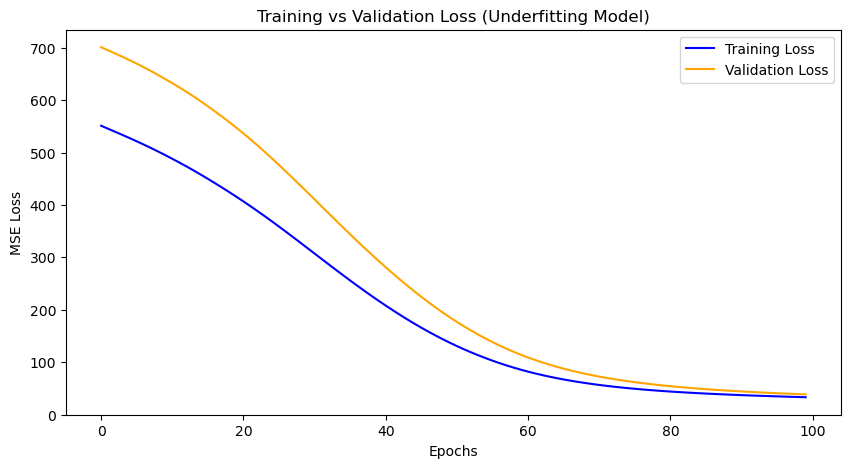

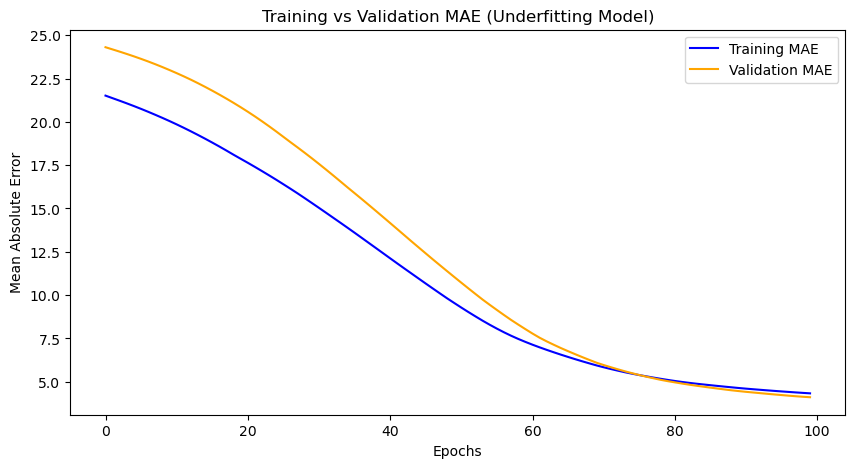

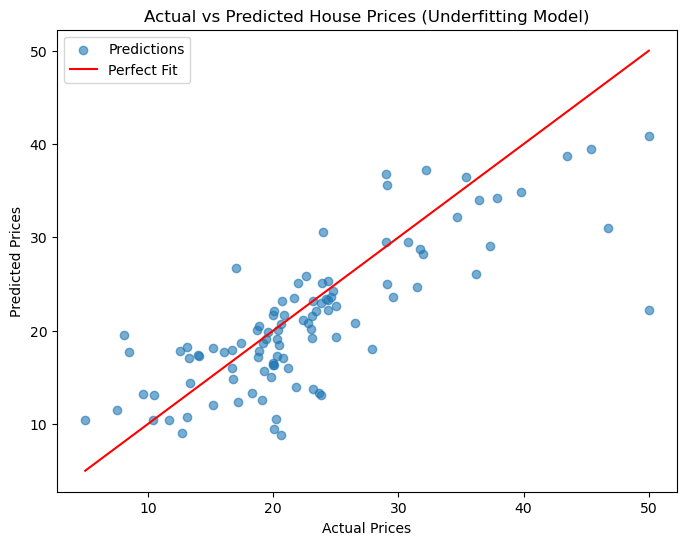

In [11]:
# Plot training vs validation Loss
plt.figure(figsize=(10, 5))
plt.plot(history_underfit.history['loss'], label='Training Loss', color='blue')
plt.plot(history_underfit.history['val_loss'], label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.title('Training vs Validation Loss (Underfitting Model)')
plt.show()

# Plot training vs validation MAE
plt.figure(figsize=(10, 5))
plt.plot(history_underfit.history['mae'], label='Training MAE', color='blue')
plt.plot(history_underfit.history['val_mae'], label='Validation MAE', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Mean Absolute Error')
plt.legend()
plt.title('Training vs Validation MAE (Underfitting Model)')
plt.show()

# Predict values for comparison
y_pred_underfit = underfitting_model.predict(X_test, verbose=0)

# Scatter plot actual vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_underfit, alpha=0.6, label="Predictions")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', label="Perfect Fit")  
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices (Underfitting Model)")
plt.legend()
plt.show()

### Underfitting Model Results
As expected, the Underfitting Model performed poorly, showing that it lacks the capacity to model the housing prices well. On the test set it reached an MSE of 33.2, an MAE of 4.15 and an R² of only 0.58.

The training and validation loss curves are still falling slowly after 100 epochs and end well above the final model's, and the scatter plot comparing actual vs predicted prices shows large deviations from the ideal line.

This outcome confirms our initial hypothesis about underfitting and emphasizes the necessity of increasing model complexity to achieve improved performance. Next, we will explore a model with increased complexity to address this limitation.

## 2- Overfitting Model:
The next stage in my investigation was to intentionally create a model that would overfit the dataset. Overfitting occurs when a model captures not only the underlying pattern but also noise from the training data, causing it to perform extremely well on training data yet poorly on unseen validation and test data.

### Model Design

To illustrate overfitting, I significantly increased the complexity of the neural network by using several dense layers with a high number of neurons:

- Input Layer: Matching the dimensionality of the input features.
- Hidden Layers: Five hidden layers with decreasing neuron counts (1024, 512, 256, 128, 64), each using a ReLU activation function.
- Output Layer: A single neuron without an activation function for regression predictions.

### Rationale

This complex architecture was deliberately designed to show how excessive complexity causes the model to memorize training data rather than learning generalizable patterns. The intention was to highlight how such complexity leads to poor performance on unseen data, despite excellent performance on the training set.

### Training Procedure

- The model was compiled using the Adam optimizer with a relatively high learning rate of 0.02. The chosen loss function was Mean Squared Error (MSE), with Mean Absolute Error (MAE) as an additional metric.
- Training was conducted for 200 epochs, with a batch size of 16 and 20% of the training data reserved for validation purposes.

### Evaluation and Expectations

The overfitting model's results were in line with expectations:

- The training loss dropped quickly and stayed low for the rest of training.
- The validation loss stayed above the training loss and kept fluctuating from epoch to epoch, with several spikes.
- This gap between training and validation error, clearest in the MAE plot, is the sign of overfitting: the model fits noise in the training data as well as the general pattern.

On the test set it reached an MSE of 12.4, an MAE of 2.09 and an R² of 0.84. That is much better than the underfitting model, but worse than the regularized final model developed below.

This experiment shows how excessive complexity hurts generalization, and why careful control of model capacity is necessary.

## Overfitting Model

In [12]:
# Define the overfitting model
def build_overfitting_model(input_shape):
    model = keras.Sequential([
        layers.Input(shape=(input_shape,)),
        layers.Dense(1024, activation='relu'),
        layers.Dense(512, activation='relu'),
        layers.Dense(256, activation='relu'),  
        layers.Dense(128, activation='relu'),  
        layers.Dense(64, activation='relu'),
        layers.Dense(1) 
    ])
    
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.02),
                  loss="mse",
                  metrics=["mae"])    
    return model

# Build the model
overfitting_model = build_overfitting_model(X_train.shape[1])

In [13]:
# Train the overfitting model
history_overfit = overfitting_model.fit(
    X_train, y_train,
    validation_split=0.2,  
    epochs=200, 
    batch_size=16,
    verbose=0
)

# Evaluate on test data
test_loss_overfit, test_mae_overfit = overfitting_model.evaluate(X_test, y_test, verbose=0)

print(f"Overfitting Model Test Loss: {test_loss_overfit}")
print(f"Overfitting Model Test MAE: {test_mae_overfit}")

Overfitting Model Test Loss: 12.369449615478516
Overfitting Model Test MAE: 2.0903100967407227


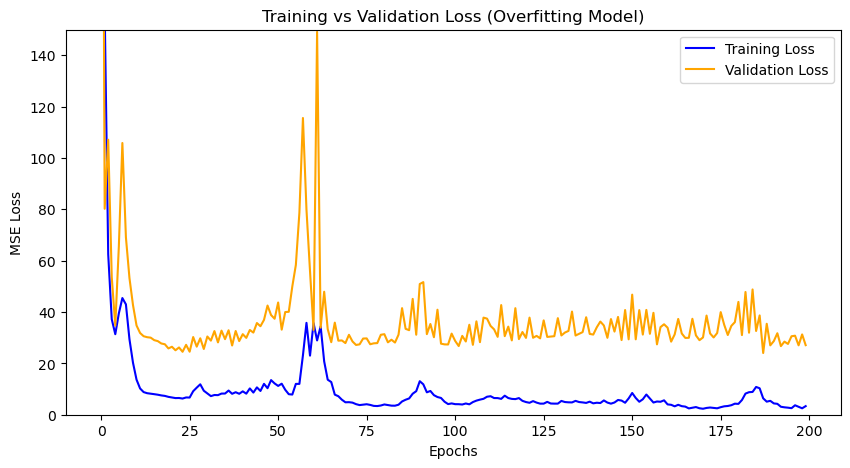

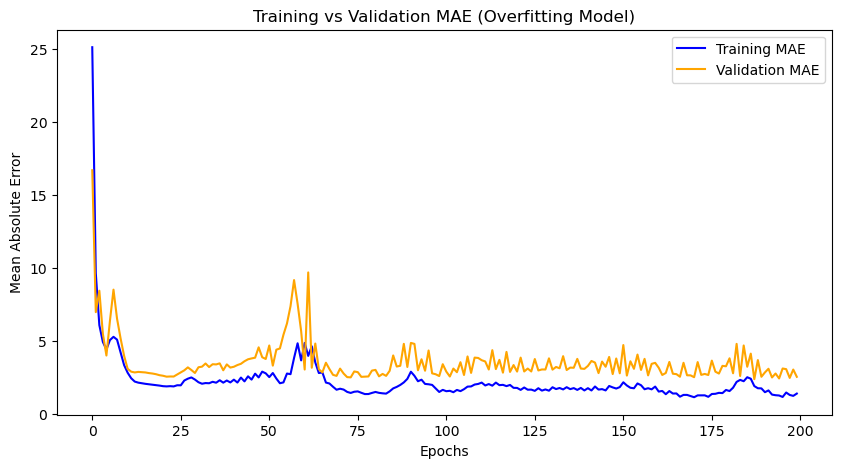

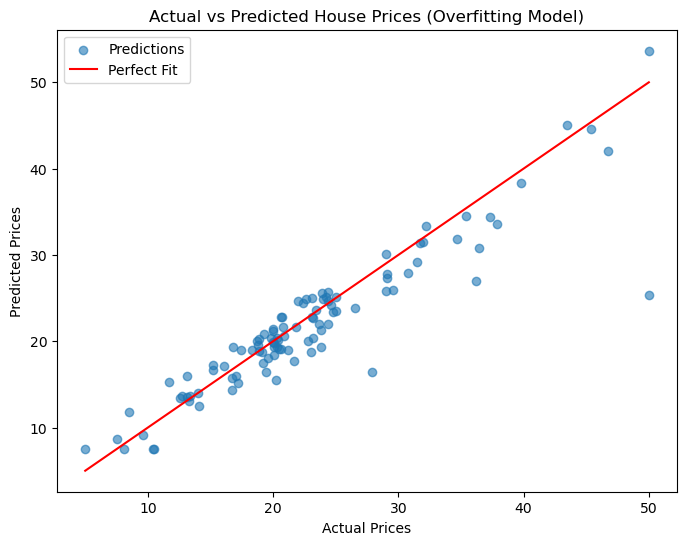

In [14]:
# Plot training vs validation loss 
plt.figure(figsize=(10, 5))
plt.plot(history_overfit.history['loss'], label='Training Loss', color='blue')
plt.plot(history_overfit.history['val_loss'], label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.ylim(0, 150)  # zoom in: the first epoch's loss is in the thousands
plt.title('Training vs Validation Loss (Overfitting Model)')
plt.show()

# Plot training vs validation MAE
plt.figure(figsize=(10, 5))
plt.plot(history_overfit.history['mae'], label='Training MAE', color='blue')
plt.plot(history_overfit.history['val_mae'], label='Validation MAE', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Mean Absolute Error')
plt.legend()
plt.title('Training vs Validation MAE (Overfitting Model)')
plt.show()

# Predict values for comparison
y_pred_overfit = overfitting_model.predict(X_test, verbose=0)

# Scatter plot actual vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_overfit, alpha=0.6, label="Predictions")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', label="Perfect Fit")  
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices (Overfitting Model)")
plt.legend()
plt.show()

## Optimizing Dropout Rate and Final Model

### Model Design and Dropout Optimization:
To address the overfitting issue identified previously, dropout regularization was introduced. Dropout randomly disables a subset of neurons during training, preventing excessive reliance on specific neurons and thus improving generalization.

The optimization process involved systematically experimenting with various dropout rates: 0.1, 0.2, 0.3, 0.4, and 0.5. Each model was trained for 100 epochs, and validation loss was monitored to identify the optimal dropout rate.

### Results of Dropout Optimization:
The best dropout rate identified was 0.1, achieving the lowest validation loss among all tested rates. Specifically, the validation losses obtained were:

- Dropout rate 0.1: 11.46
- Dropout rate 0.2: 11.78
- Dropout rate 0.3: 11.82
- Dropout rate 0.4: 11.87
- Dropout rate 0.5: 12.79

Rates up to 0.4 perform similarly and 0.1 was the best of them, while the highest rate (0.5) was clearly worse.

### Final Model Implementation:
Based on the optimized dropout rate, the final neural network architecture comprised three hidden Dense layers with 128, 64, and 32 neurons respectively, each followed by Dropout layers at the optimized rate (0.1). The model was compiled with the Adam optimizer, MSE loss function, and monitored with MAE as a performance metric.

Training utilized early stopping (patience = 10 epochs) to automatically halt when no further improvement in validation loss was observed. The final model achieved a test MSE of 8.65, an MAE of 2.06 and an R² of 0.89, indicating that the model captures the underlying data patterns well.

Overall, this systematic approach demonstrated the efficacy of dropout regularization in achieving robust performance, striking a balance between complexity and generalization capability.


## Optimizing Dropout Rate

In [15]:
# tracking variables
best_dropout = 0
best_val_loss = float('inf')
dropout_results = {}

for dropout_rate in [0.1, 0.2, 0.3, 0.4, 0.5]:     
    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout_rate),  
        layers.Dense(64, activation='relu'),
        layers.Dropout(dropout_rate),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='linear')
    ])
    
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    # Train model
    history = model.fit(
        X_train, y_train, 
        validation_data=(X_val, y_val), 
        epochs=100, 
        verbose=0 
    )
    
    final_val_loss = history.history['val_loss'][-1] 
    dropout_results[dropout_rate] = final_val_loss
    
    if final_val_loss < best_val_loss:
        best_val_loss = final_val_loss
        best_dropout = dropout_rate

print(f"Best dropout rate found: {best_dropout}")
print(dropout_results) 


Best dropout rate found: 0.1
{0.1: 11.461620330810547, 0.2: 11.776034355163574, 0.3: 11.824650764465332, 0.4: 11.87143611907959, 0.5: 12.787201881408691}


# Final Model

Based on the optimal dropout rate identified (0.1), we constructed a final model to mitigate the overfitting observed previously. The final architecture includes strategically placed dropout layers, ensuring regularization, along with an optimized complexity.

### Model Structure:
- Input Layer: Matches the input feature dimensionality.
- Hidden Layers: Dense layers with 128, 64, and 32 neurons using ReLU activation functions, each followed by dropout layers with the best dropout rate (0.1).
- Output Layer: Single neuron for regression output.

### Training Procedure:
The final model was compiled using the Adam optimizer, Mean Squared Error (MSE) loss, and Mean Absolute Error (MAE) as the evaluation metric. To avoid overfitting, we utilized an early stopping callback that monitored validation loss with a patience of 10 epochs.

### Final Model Results:
The Final Model outperformed both the Underfitting and Overfitting models, achieving a Mean Squared Error (MSE) of 8.65, a Mean Absolute Error (MAE) of 2.06 and an R² score of 0.89 on the test set (the overfitting model scored 12.37, 2.09 and 0.84, and the underfitting model 33.2, 4.15 and 0.58). The validation loss plots demonstrate the final model’s superior stability and convergence, outperforming other models by consistently maintaining low validation errors throughout training epochs.

This optimal configuration strikes a balance between model complexity and regularization, addressing previous limitations effectively and accurately capturing the underlying housing price patterns in the dataset.

The results show that a smaller, regularized network trained with early stopping generalizes better than either extreme.

## Final Model

In [16]:
# Define the final model
def build_final_model(input_shape, dropout_rate):
    model = keras.Sequential([
        layers.Input(shape=(input_shape,)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout_rate),
        layers.Dense(64, activation='relu'),
        layers.Dropout(dropout_rate),
        layers.Dense(32, activation='relu'),
        layers.Dense(1)
    ])
    
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model
    
# Build the model
final_model = build_final_model(X_train.shape[1], best_dropout)

### Early Stopping
To prevent overfitting, I employed an early stopping mechanism. I monitored the validation loss during training and if the validation loss stopped decreasing for a certain number of consecutive epochs, I halted training. This means the model stops training at the point when further training would only make it better at the training data but not improve validation performance. Early stopping ensured I didn't over train the model beyond the point of generalization.

In [17]:
# Define early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True
)

# Train the final model
history_final = final_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=250,
    callbacks=[early_stopping],
    batch_size=16,
    verbose=0
)

print(f"Early stopping ended training after {len(history_final.history['loss'])} epochs")

# Evaluate on test data
test_loss_final, test_mae_final = final_model.evaluate(X_test, y_test, verbose=0)

print(f"Final Model Test Loss: {test_loss_final}")
print(f"Final Model Test MAE: {test_mae_final}")

Early stopping ended training after 60 epochs
Final Model Test Loss: 8.646159172058105
Final Model Test MAE: 2.0641634464263916


## Models Comparison

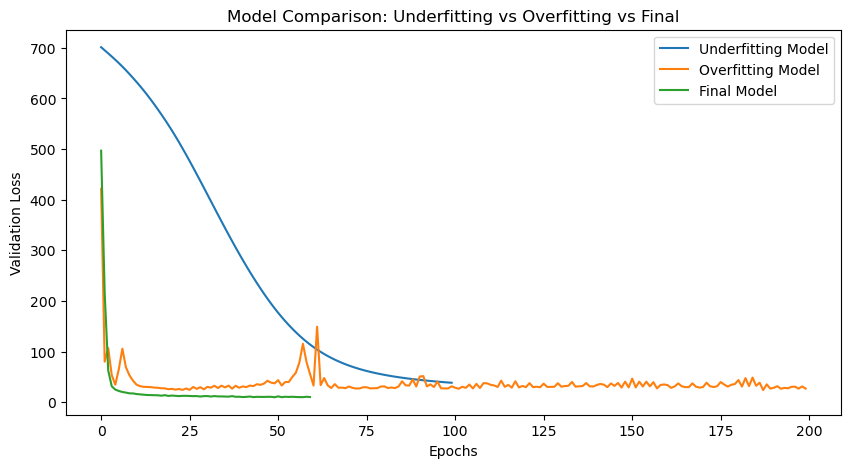

In [18]:
# Compare validation loss for all models
plt.figure(figsize=(10, 5))
plt.plot(history_underfit.history['val_loss'], label="Underfitting Model")
plt.plot(history_overfit.history['val_loss'], label="Overfitting Model")
plt.plot(history_final.history['val_loss'], label="Final Model")
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.legend()
plt.title("Model Comparison: Underfitting vs Overfitting vs Final")
plt.show()

## Evaluate all models

In [19]:
# Evaluate models
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test, verbose=0)
    mse = mean_squared_error(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    return mse, mae, r2

metrics_underfit = evaluate_model(underfitting_model, X_test, y_test)
metrics_overfit = evaluate_model(overfitting_model, X_test, y_test)
metrics_final = evaluate_model(final_model, X_test, y_test)

print(f"Underfitting Model: MSE={metrics_underfit[0]}, MAE={metrics_underfit[1]}, R²={metrics_underfit[2]}")
print(f"Overfitting Model: MSE={metrics_overfit[0]}, MAE={metrics_overfit[1]}, R²={metrics_overfit[2]}")
print(f"Final Model: MSE={metrics_final[0]}, MAE={metrics_final[1]}, R²={metrics_final[2]}")


Underfitting Model: MSE=33.206852869349504, MAE=4.152165839251349, R²=0.5750396110801066
Overfitting Model: MSE=12.369448099245808, MAE=2.090310033162435, R²=0.8417035936629875
Final Model: MSE=8.646159532603551, MAE=2.06416348289041, R²=0.8893518957639593


## Results Summary

,MSE,MAE,R²
Underfitting,33.207,4.152,0.575
Overfitting,12.369,2.090,0.842
Final (dropout + early stopping),8.646,2.064,0.889


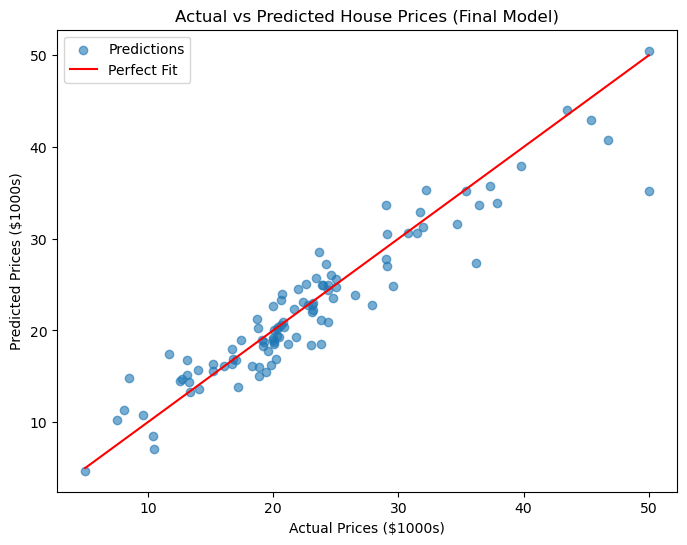

In [20]:
results = pd.DataFrame(
    [metrics_underfit, metrics_overfit, metrics_final],
    index=["Underfitting", "Overfitting", "Final (dropout + early stopping)"],
    columns=["MSE", "MAE", "R²"],
).round(3)
display(results)

# Actual vs predicted prices for the final model
y_pred_final = final_model.predict(X_test, verbose=0).ravel()
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_final, alpha=0.6, label="Predictions")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', label="Perfect Fit")
plt.xlabel("Actual Prices ($1000s)")
plt.ylabel("Predicted Prices ($1000s)")
plt.title("Actual vs Predicted House Prices (Final Model)")
plt.legend()
plt.show()

# Conclusion
In this project, I successfully built a deep learning model to predict housing prices and learned valuable lessons about the machine learning workflow. I started by thoroughly preprocessing the data (handling missing values, scaling features, and splitting the dataset) which set a solid foundation for modeling. Through experimenting with model architectures, I observed the extremes of underfitting and overfitting. The underfitting model taught me that too little model complexity cannot capture important patterns, while the overfitting model highlighted the dangers of excessive complexity without regularization. Using techniques like dropout regularization, early stopping, and careful hyperparameter tuning, I developed a final neural network model that provided a good balance between bias and variance. The final model demonstrated strong performance on unseen test data, indicated by a low error (MSE/MAE) and a high R², meaning it can explain a large portion of the variance in housing prices.